In [ ]:
!pip -q install kagglehub

import kagglehub, glob, os, re, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
from torch.utils.data import Dataset, DataLoader

path = kagglehub.dataset_download("lakshmi25npathi/imdb-dataset-of-50k-movie-reviews")
file = glob.glob(path + "/**/IMDB Dataset.csv", recursive=True)[0]
df = pd.read_csv(file)

print(df.shape)
print(df.head())

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
(50000, 2)
                                              review sentiment
0  One of the other reviewers has mentioned that ...  positive
1  A wonderful little production. <br /><br />The...  positive
2  I thought this was a wonderful way to spend ti...  positive
3  Basically there's a family where a little boy ...  negative
4  Petter Mattei's "Love in the Time of Money" is...  positive


In [ ]:
df["label"] = df["sentiment"].map({"positive": 1, "negative": 0})

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

texts = df["review"].apply(tokenize).tolist()
labels = df["label"].tolist()

vocab = {"<PAD>": 0, "<UNK>": 1}
for word, _ in Counter(w for review in texts for w in review).most_common(20000):
    if word not in vocab:
        vocab[word] = len(vocab)

MAX_LEN = 200

def encode(words):
    ids = [vocab.get(w, 1) for w in words[:MAX_LEN]]
    return ids + [0] * (MAX_LEN - len(ids))

X = np.array([encode(t) for t in texts])
y = np.array(labels)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Vocabulary size:", len(vocab))

Train: (40000, 200) Test: (10000, 200)
Vocabulary size: 20002


In [ ]:
class Reviews(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

train_loader = DataLoader(
    Reviews(X_train, y_train), batch_size=128, shuffle=True
)
test_loader = DataLoader(
    Reviews(X_test, y_test), batch_size=128
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


In [ ]:
class LSTMModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed = nn.Embedding(len(vocab), 64, padding_idx=0)
        self.lstm = nn.LSTM(64, 64, batch_first=True)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        x = self.embed(x)
        _, (h, _) = self.lstm(x)
        return self.fc(h[-1]).squeeze(1)

model = LSTMModel().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print(model)

LSTMModel(
  (embed): Embedding(20002, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [ ]:
train_losses = []

for epoch in range(3):
    model.train()
    total_loss = 0

    for Xb, yb in train_loader:
        Xb, yb = Xb.to(device), yb.to(device)

        optimizer.zero_grad()
        output = model(Xb)
        loss = criterion(output, yb)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    print(f"Epoch {epoch+1}: Loss = {avg_loss:.4f}")

Epoch 1: Loss = 0.6926
Epoch 2: Loss = 0.6905
Epoch 3: Loss = 0.6833


In [ ]:
model.eval()
y_true, probs = [], []

with torch.no_grad():
    for Xb, yb in test_loader:
        out = torch.sigmoid(model(Xb.to(device))).cpu()
        probs.extend(out.numpy())
        y_true.extend(yb.numpy())

y_pred = (np.array(probs) >= 0.5).astype(int)

print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print(classification_report(y_true, y_pred, target_names=["Negative", "Positive"]))

Accuracy: 49.8 %
              precision    recall  f1-score   support

    Negative       0.50      0.23      0.32      5000
    Positive       0.50      0.76      0.60      5000

    accuracy                           0.50     10000
   macro avg       0.50      0.50      0.46     10000
weighted avg       0.50      0.50      0.46     10000



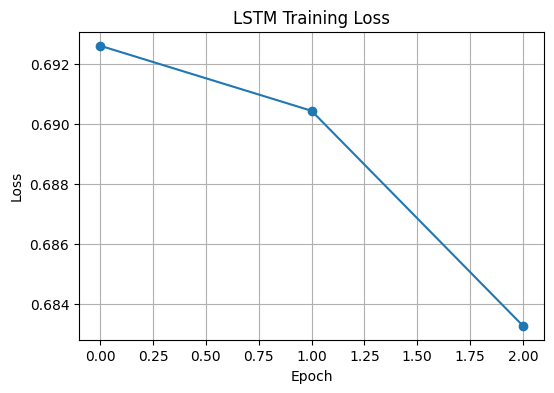

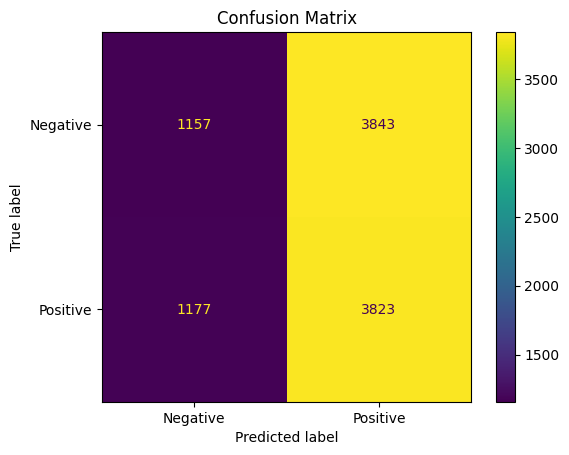

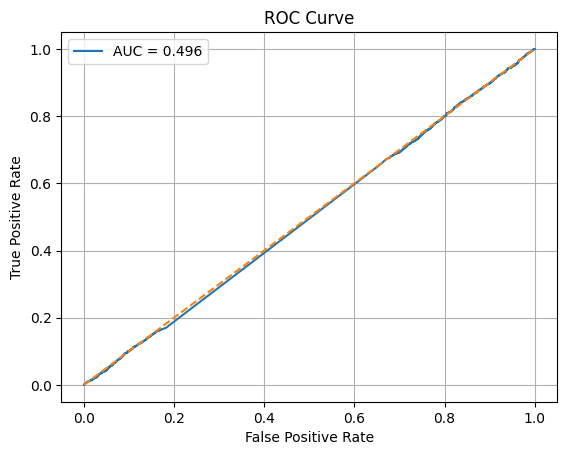

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(train_losses, marker="o")
plt.title("LSTM Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()
plt.show()

ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, display_labels=["Negative", "Positive"]
)
plt.title("Confusion Matrix")
plt.show()

fpr, tpr, _ = roc_curve(y_true, probs)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

In [ ]:
class Baseline(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embed = nn.Embedding(vocab_size, 64, padding_idx=0)
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        e = self.embed(x)
        mask = (x != 0).unsqueeze(-1)
        pooled = (e * mask).sum(1) / mask.sum(1).clamp(min=1)
        return self.fc(pooled).squeeze(1)

# Ensure device, loaders, and loss criterion are defined
if 'device' not in globals():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if 'Reviews' not in globals():
    class Reviews(Dataset):
        def __init__(self, X, y):
            self.X = torch.tensor(X, dtype=torch.long)
            self.y = torch.tensor(y, dtype=torch.float32)
        def __len__(self):
            return len(self.y)
        def __getitem__(self, i):
            return self.X[i], self.y[i]

if 'train_loader' not in globals() or 'test_loader' not in globals():
    train_loader = DataLoader(
        Reviews(X_train, y_train), batch_size=128, shuffle=True
    )
    test_loader = DataLoader(
        Reviews(X_test, y_test), batch_size=128
    )

if 'criterion' not in globals():
    criterion = nn.BCEWithLogitsLoss()

vocab_size = len(vocab) if 'vocab' in globals() else 20002
base = Baseline(vocab_size).to(device)
opt = torch.optim.Adam(base.parameters(), lr=0.001)

for epoch in range(3):
    base.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        opt.zero_grad()
        loss = criterion(base(xb), yb)
        loss.backward()
        opt.step()

base.eval()
base_preds = []

if 'y_true' not in globals():
    y_true = []
    with torch.no_grad():
        for _, yb in test_loader:
            y_true.extend(yb.numpy())

with torch.no_grad():
    for xb, _ in test_loader:
        base_preds.extend(
            (torch.sigmoid(base(xb.to(device))).cpu().numpy() >= 0.5).astype(int)
        )

print("Baseline Accuracy:\n", round(accuracy_score(y_true, base_preds) * 100, 2), "%")
if 'y_pred' in globals():
    print("LSTM Accuracy:\n", round(accuracy_score(y_true, y_pred) * 100, 2), "%")

NameError: name 'X_train' is not defined